<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/lesson9/Lesson9_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 9 — Derivatives and Sensitivity: How Fast Does a Response Change?

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 3 — Calculus I\
**Lesson:** Lesson 9\
**Notebook type:** Teaching notebook

> *"A neuron that changes its rate a lot for a small change of input is sensitive there. The derivative is the number that says how sensitive, in spikes/s per unit of input."*

---

### From functions to rates of change

Lesson 8 described **what** a response function is. This lesson asks **how fast it changes**. The answer, the **derivative**, appears everywhere in this course. It turns position into velocity and velocity into acceleration. It says how much a neuron's rate changes per unit of contrast, current or speed (its **sensitivity**). In Lesson 10 it shows how much a network's error changes per unit change of each weight, which is how networks learn. And in Lesson 21 it is the "$dV/dt$" of every differential equation.

The derivative is a limit, the limit of the slope through two nearby points. You will compute it with rules, approximate it with **finite differences**, and see why differentiating real, noisy data is a delicate business. The mini-lab differentiates a monkey's recorded hand position, checks the result against independently recorded velocity, and asks whether motor-cortex neurons care about acceleration.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-8.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-8.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: where is a neuron most sensitive?**

Lesson 8 fitted a saturating function to a motor-cortex neuron's firing rate as a function of hand speed:

$$r(s) = r_0 + A\big(1 - e^{-s/s_0}\big), \qquad r_0 = 44.8\ \text{spikes/s},\ A = 59.8\ \text{spikes/s},\ s_0 = 11.0\ \text{cm/s}.$$

Increase the speed by the same 2 cm/s at three different starting speeds. How much does the rate change?

speed  1 ->  3 cm/s: rate  50.00 ->  59.07 spikes/s, change  9.08
speed 10 -> 12 cm/s: rate  80.51 ->  84.51 spikes/s, change  4.01
speed 30 -> 32 cm/s: rate 100.69 -> 101.34 spikes/s, change  0.65


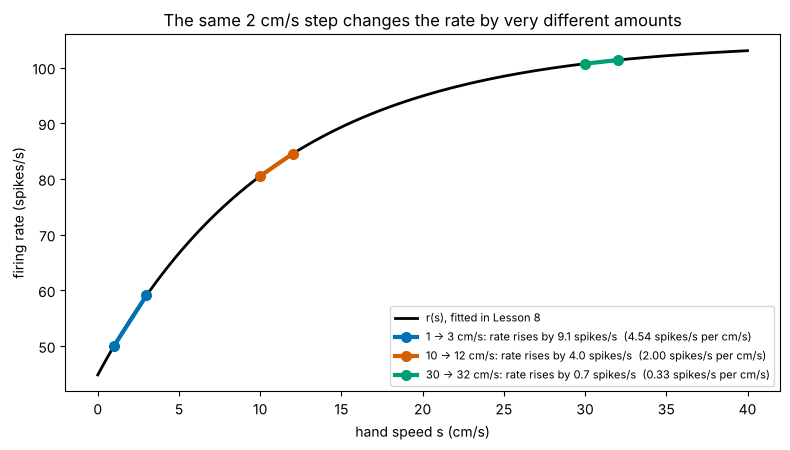

In [3]:
r0, A, s0 = 44.8, 59.8, 11.0
def rate_of_speed(s):
    return r0 + A * (1 - np.exp(-s / s0))                       # spikes/s, s in cm/s

s = np.linspace(0, 40, 401)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(s, rate_of_speed(s), color='black', lw=2, label='r(s), fitted in Lesson 8')
for s_start, colour in zip([1, 10, 30], PALETTE):
    s_end = s_start + 2
    dr = rate_of_speed(s_end) - rate_of_speed(s_start)
    ax.plot([s_start, s_end], [rate_of_speed(s_start), rate_of_speed(s_end)], 'o-', color=colour, lw=3, ms=7,
            label=f'{s_start} -> {s_end} cm/s: rate rises by {dr:.1f} spikes/s  ({dr / 2:.2f} spikes/s per cm/s)')
    print(f"speed {s_start:>2} -> {s_end:>2} cm/s: rate {rate_of_speed(s_start):6.2f} -> {rate_of_speed(s_end):6.2f} spikes/s, change {dr:5.2f}")
ax.set_xlabel('hand speed s (cm/s)'); ax.set_ylabel('firing rate (spikes/s)')
ax.set_title('The same 2 cm/s step changes the rate by very different amounts'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

At slow speeds the neuron is about **fourteen times more sensitive** than at fast speeds. The ratio "change in rate / change in speed" is a slope in spikes/s per cm/s, but it depends on where you measure it and on how big a step you take. The **derivative** removes the second dependence by letting the step shrink to zero, giving one number for each speed: the sensitivity of the neuron at exactly that speed.

# **Part 1: From Secant to Tangent — the Derivative as a Limit**

The **difference quotient**

$$\frac{f(x + h) - f(x)}{h}$$

is the slope of the **secant** line through the points $(x, f(x))$ and $(x + h, f(x + h))$: rise over run. As $h$ shrinks, the secant swings towards the **tangent** line, which touches the curve at $x$ and points along it. The **derivative** is the slope of the tangent, defined as the limit (Lesson 8):

$$f'(x) = \frac{df}{dx}(x) = \lim_{h \to 0}\frac{f(x + h) - f(x)}{h}.$$

If the limit exists, $f$ is **differentiable** at $x$.

**Units.** A derivative has the units of the output **per** unit of the input: spikes/s per cm/s for $dr/ds$, mV per ms for $dV/dt$, cm/s per s (= cm/s$^2$) for the derivative of velocity. Always state them.

  h (cm/s)   secant slope (spikes/s per cm/s)
        10                           2.266463
         5                           2.772879
         2                           3.155140
         1                           3.298457
       0.1                           3.435021
      0.01                           3.449090
     0.001                           3.450501
     limit                           3.450658   <- the derivative r'(5)


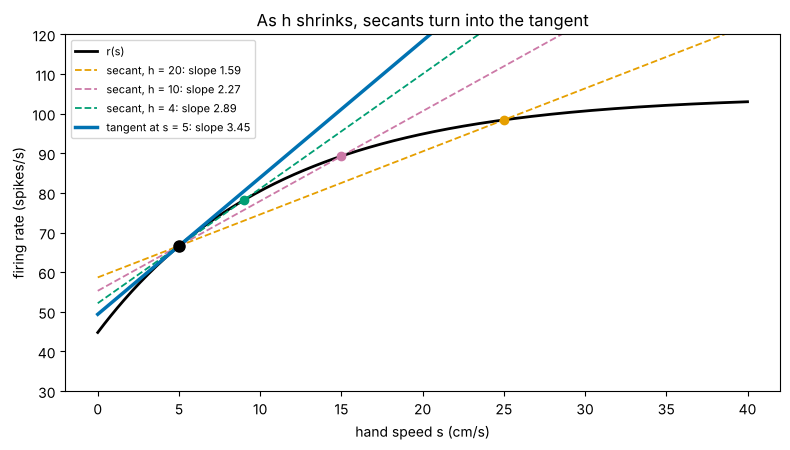

In [4]:
x0 = 5.0
exact_slope = A / s0 * np.exp(-x0 / s0)                           # the derivative, worked out with the rules of Part 2
print(f"{'h (cm/s)':>10} {'secant slope (spikes/s per cm/s)':>34}")
for h in [10, 5, 2, 1, 0.1, 0.01, 0.001]:
    print(f"{h:>10} {(rate_of_speed(x0 + h) - rate_of_speed(x0)) / h:>34.6f}")
print(f"{'limit':>10} {exact_slope:>34.6f}   <- the derivative r'(5)")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(s, rate_of_speed(s), color='black', lw=2, label='r(s)')
for h, colour in zip([20, 10, 4], [PALETTE[4], PALETTE[3], PALETTE[2]]):
    slope = (rate_of_speed(x0 + h) - rate_of_speed(x0)) / h
    ax.plot(s, rate_of_speed(x0) + slope * (s - x0), color=colour, lw=1.3, ls='--', label=f'secant, h = {h}: slope {slope:.2f}')
    ax.plot(x0 + h, rate_of_speed(x0 + h), 'o', color=colour)
ax.plot(s, rate_of_speed(x0) + exact_slope * (s - x0), color=PALETTE[0], lw=2.5, label=f'tangent at s = {x0:.0f}: slope {exact_slope:.2f}')
ax.plot(x0, rate_of_speed(x0), 'ko', ms=8)
ax.set_ylim(30, 120); ax.set_xlabel('hand speed s (cm/s)'); ax.set_ylabel('firing rate (spikes/s)')
ax.set_title('As h shrinks, secants turn into the tangent'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Animation: shrink h and watch the secant become the tangent

In [5]:
h_values = [25, 18, 12, 8, 5, 3, 2, 1, 0.5, 0.1]
def secant_line(h):
    slope = (rate_of_speed(x0 + h) - rate_of_speed(x0)) / h
    return rate_of_speed(x0) + slope * (s - x0), slope
y0_, sl0 = secant_line(h_values[0])
fig_sec = go.Figure([
    go.Scatter(x=s, y=rate_of_speed(s), mode='lines', line=dict(color='black', width=3), name='r(s)'),
    go.Scatter(x=s, y=rate_of_speed(x0) + exact_slope * (s - x0), mode='lines', line=dict(color=PALETTE[0], width=2, dash='dot'), name='tangent'),
    go.Scatter(x=s, y=y0_, mode='lines', line=dict(color=PALETTE[1], width=3), name='secant'),
    go.Scatter(x=[x0, x0 + h_values[0]], y=[rate_of_speed(x0), rate_of_speed(x0 + h_values[0])], mode='markers', marker=dict(size=11, color=PALETTE[1]), name='the two points'),
])
fig_sec.frames = [go.Frame(name=str(k), traces=[2, 3], data=[go.Scatter(x=s, y=np.round(secant_line(h)[0], 3)),
                                                             go.Scatter(x=[x0, x0 + h], y=[rate_of_speed(x0), rate_of_speed(x0 + h)])],
                           layout=go.Layout(title=f'h = {h} cm/s: secant slope {secant_line(h)[1]:.3f}  (derivative {exact_slope:.3f}) spikes/s per cm/s'))
                  for k, h in enumerate(h_values)]
buttons, sliders = play_pause_and_slider(h_values, prefix='h = ', duration=500)
fig_sec.update_layout(title=fig_sec.frames[0].layout.title.text, xaxis_title='hand speed s (cm/s)', yaxis_title='firing rate (spikes/s)', yaxis_range=[30, 120],
                      template='plotly_white', width=850, height=500, updatemenus=buttons, sliders=sliders)
fig_sec.show(config=PLOTLY_CONFIG)

### The derivative is itself a function

Computing $f'(x)$ at every $x$ gives a new function $f'$. Where $f$ rises, $f' > 0$; where it falls, $f' < 0$; at a peak or a trough, $f' = 0$ (Lesson 11 builds on this); where $f$ is steepest, $|f'|$ is largest.

### Where derivatives fail

Differentiable implies continuous, but not the other way round. At a **corner** the left and right secant slopes approach different values, so the limit does not exist. ReLU at 0 has left slope 0 and right slope 1; $|x|$ at 0 has $-1$ and $+1$. At a jump (the step function) the difference quotient grows without bound. Deep-learning software simply **chooses** a value at ReLU's corner (usually 0); since hitting exactly 0 is rare, this convention almost never matters.

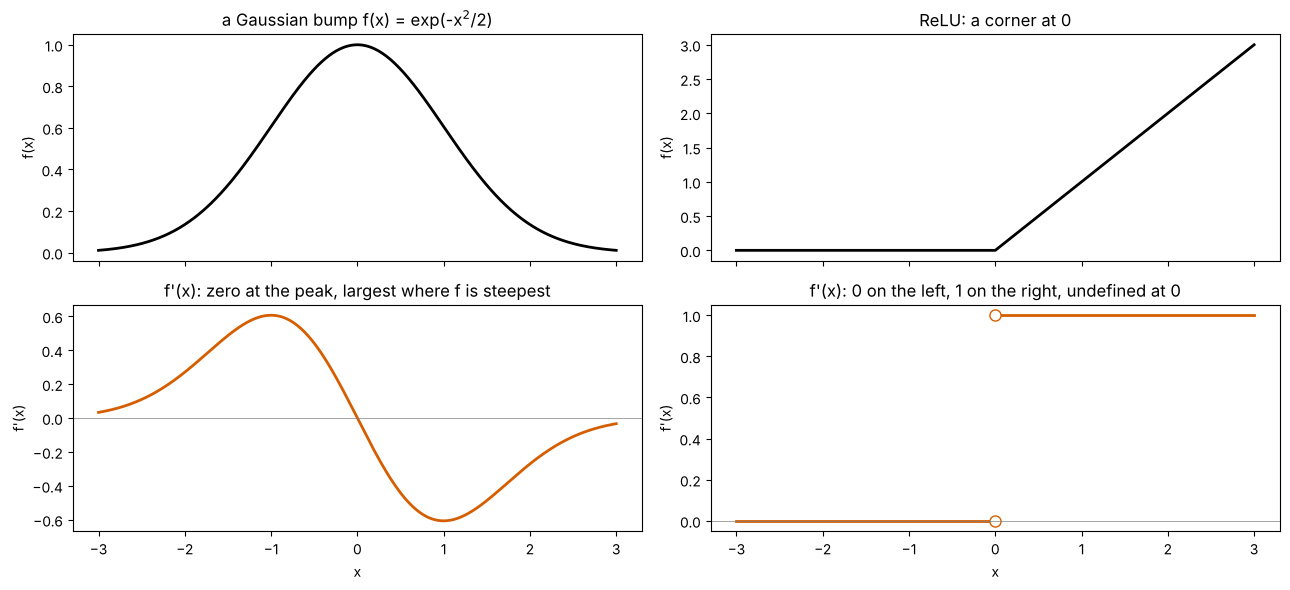

In [6]:
xs = np.linspace(-3, 3, 601)
curves = [('a Gaussian bump f(x) = exp(-x$^2$/2)', np.exp(-xs**2 / 2), -xs * np.exp(-xs**2 / 2)),
          ('ReLU: a corner at 0', np.maximum(xs, 0), np.where(xs > 0, 1.0, 0.0))]
fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
for col, (title, f, df) in enumerate(curves):
    axes[0, col].plot(xs, f, color='black', lw=2); axes[0, col].set_title(title); axes[0, col].set_ylabel('f(x)')
    if col == 1:
        axes[1, col].plot(xs[xs < 0], df[xs < 0], color=PALETTE[1], lw=2); axes[1, col].plot(xs[xs > 0], df[xs > 0], color=PALETTE[1], lw=2)
        axes[1, col].plot(0, 0, 'o', mfc='white', mec=PALETTE[1], ms=8); axes[1, col].plot(0, 1, 'o', mfc='white', mec=PALETTE[1], ms=8)
        axes[1, col].set_title("f'(x): 0 on the left, 1 on the right, undefined at 0")
    else:
        axes[1, col].plot(xs, df, color=PALETTE[1], lw=2); axes[1, col].set_title("f'(x): zero at the peak, largest where f is steepest")
    axes[1, col].axhline(0, color='grey', lw=0.5); axes[1, col].set_xlabel('x'); axes[1, col].set_ylabel("f'(x)")
plt.tight_layout(); plt.show()

# **Part 2: Derivative Rules**

Computing every derivative from the limit would be slow. A few rules, each proved once from the definition (see the notes), cover almost everything:

| Rule | Formula |
|---|---|
| constant | $\frac{d}{dx}c = 0$ |
| power | $\frac{d}{dx}x^n = n x^{n-1}$ (any real $n$, where defined) |
| constant multiple, sum | $(af + bg)' = af' + bg'$ (**linearity**) |
| product | $(fg)' = f'g + fg'$ |
| quotient | $\left(\frac{f}{g}\right)' = \frac{f'g - fg'}{g^2}$ |
| exponential | $\frac{d}{dx}e^{x} = e^{x}$, and $\frac{d}{dx}e^{ax} = a e^{ax}$ |
| logarithm | $\frac{d}{dx}\ln x = \frac{1}{x}$ for $x > 0$ |
| sine, cosine | $\frac{d}{dx}\sin x = \cos x$, $\frac{d}{dx}\cos x = -\sin x$ (angles in radians) |

$e^x$ is special: it is its own derivative, which is why exponentials describe processes whose rate of change is proportional to their size (decay, growth; Lessons 6 and 21). The rule $\frac{d}{dx}e^{ax} = ae^{ax}$ is the first case of the **chain rule**, which Lesson 10 develops fully.

**Example.** For the motivating neuron, $r(s) = r_0 + A - Ae^{-s/s_0}$, so by linearity and the exponential rule

$$r'(s) = -A\cdot\left(-\frac{1}{s_0}\right)e^{-s/s_0} = \frac{A}{s_0}e^{-s/s_0}\quad\text{spikes/s per cm/s}.$$

The sensitivity is largest at $s = 0$, where it equals $A/s_0 \approx 5.4$ spikes/s per cm/s, and halves every $s_0\ln 2 \approx 7.6$ cm/s.

### Checking a derivative numerically

A derivative worked out by hand can be checked with the **central difference** $\frac{f(x + h) - f(x - h)}{2h}$ for a small $h$ (Part 4 explains why central, and why not too small). This "gradient check" is standard practice when implementing learning algorithms (Lesson 10).

In [7]:
def central_diff(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)

checks = [
    ('x^3',             lambda x: x**3,               lambda x: 3 * x**2),
    ('sqrt(x)',         lambda x: np.sqrt(x),         lambda x: 0.5 / np.sqrt(x)),
    ('x^2 e^x (product)', lambda x: x**2 * np.exp(x), lambda x: (2 * x + x**2) * np.exp(x)),
    ('ln(x)/x (quotient)', lambda x: np.log(x) / x,   lambda x: (1 - np.log(x)) / x**2),
    ('r(s) (motivation)', rate_of_speed,              lambda x: A / s0 * np.exp(-x / s0)),
]
xt = np.array([0.5, 1.0, 2.0, 5.0])
for name, f, df in checks:
    num, exact = central_diff(f, xt), df(xt)
    print(f"{name:<20} rule: {np.round(exact, 5)}   numerical: {np.round(num, 5)}   largest relative difference {np.max(np.abs(num - exact) / np.abs(exact)):.1e}")

x^3                  rule: [ 0.75  3.   12.   75.  ]   numerical: [ 0.75  3.   12.   75.  ]   largest relative difference 1.3e-10
sqrt(x)              rule: [0.70711 0.5     0.35355 0.22361]   numerical: [0.70711 0.5     0.35355 0.22361]   largest relative difference 5.1e-11
x^2 e^x (product)    rule: [2.06090000e+00 8.15485000e+00 5.91124500e+01 5.19446057e+03]   numerical: [2.06090000e+00 8.15485000e+00 5.91124500e+01 5.19446057e+03]   largest relative difference 1.2e-10
ln(x)/x (quotient)   rule: [ 6.77259  1.       0.07671 -0.02438]   numerical: [ 6.77259  1.       0.07671 -0.02438]   largest relative difference 5.9e-10
r(s) (motivation)    rule: [5.19479 4.96395 4.53258 3.45066]   numerical: [5.19479 4.96395 4.53258 3.45066]   largest relative difference 4.4e-11


### Derivatives of activation functions

The activations of Lesson 8 have simple derivatives, worth knowing by heart because learning (Lessons 10 and 12) multiplies them together:

| Activation | Derivative | Largest value |
|---|---|---|
| logistic $\sigma(x)$ | $\sigma'(x) = \sigma(x)\big(1 - \sigma(x)\big)$ | $1/4$, at $x = 0$ |
| $\tanh x$ | $1 - \tanh^2 x$ | $1$, at $x = 0$ |
| ReLU $\max(0, x)$ | $0$ for $x < 0$, $1$ for $x > 0$ (undefined at 0) | $1$ |
| softplus $\ln(1 + e^x)$ | $\sigma(x)$ | approaches 1 |

The derivatives of $\sigma$ and $\tanh$ are tiny once $|x|$ is more than a few units: the activation is **saturated**, a small change of input barely changes the output. This is the origin of **vanishing gradients** (Lesson 10). ReLU's slope is exactly 1 wherever it is active, one reason it trains well in deep networks.

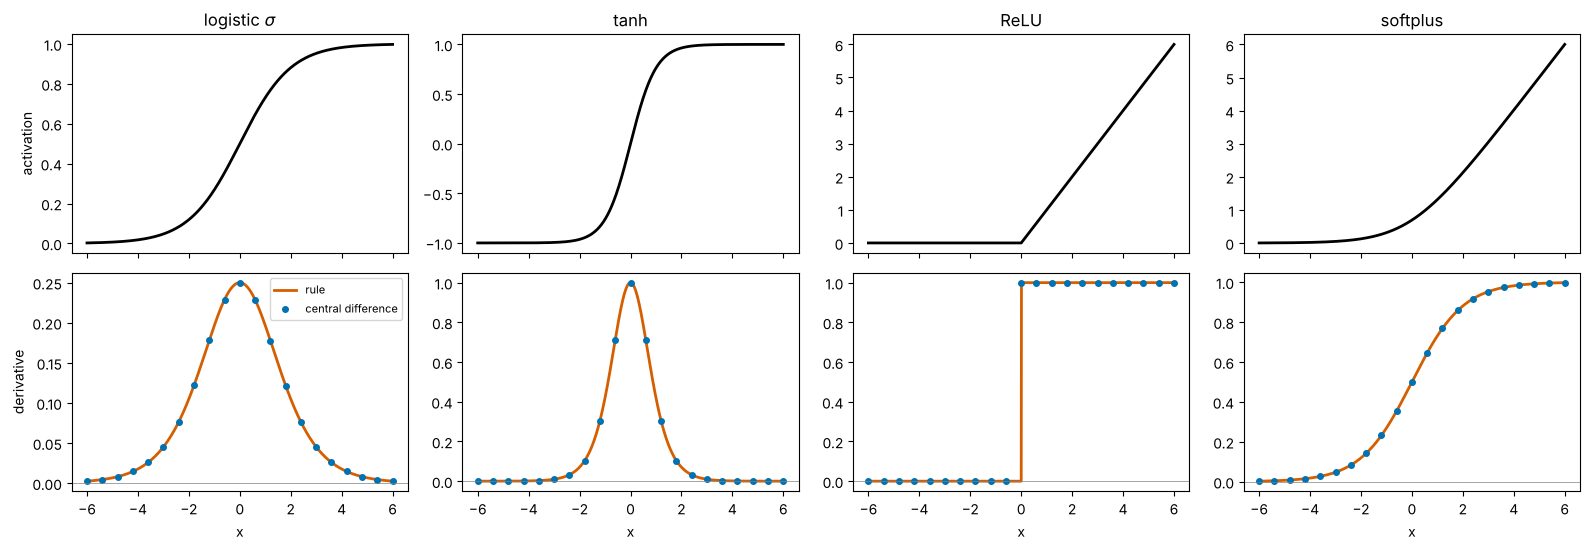

sigma'(0) = 0.2500;  sigma'(5) = 0.00665;  sigma'(10) = 4.54e-05


In [8]:
xa = np.linspace(-6, 6, 1201)
acts = [('logistic $\\sigma$', sigmoid(xa), sigmoid(xa) * (1 - sigmoid(xa))),
        ('tanh', np.tanh(xa), 1 - np.tanh(xa)**2),
        ('ReLU', np.maximum(xa, 0), np.where(xa > 0, 1.0, 0.0)),
        ('softplus', np.log1p(np.exp(-np.abs(xa))) + np.maximum(xa, 0), sigmoid(xa))]
fig, axes = plt.subplots(2, 4, figsize=(16, 5.6), sharex=True)
for col, (name, f, df) in enumerate(acts):
    axes[0, col].plot(xa, f, color='black', lw=2); axes[0, col].set_title(name)
    axes[1, col].plot(xa, df, color=PALETTE[1], lw=2, label='rule')
    axes[1, col].plot(xa[::60], central_diff(lambda z, k=col: [sigmoid(z), np.tanh(z), np.maximum(z, 0), np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0)][k], xa[::60] + 1e-3),
                      'o', ms=4, color=PALETTE[0], label='central difference')
    axes[1, col].set_xlabel('x'); axes[1, col].axhline(0, color='grey', lw=0.5)
axes[0, 0].set_ylabel('activation'); axes[1, 0].set_ylabel('derivative'); axes[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"sigma'(0) = {sigmoid(0) * (1 - sigmoid(0)):.4f};  sigma'(5) = {sigmoid(5) * (1 - sigmoid(5)):.5f};  sigma'(10) = {sigmoid(10) * (1 - sigmoid(10)):.2e}")

# **Part 3: Local Linear Approximation and Sensitivity**

Near a point $x$, a differentiable function looks like its tangent line:

$$f(x + \Delta x) \approx f(x) + f'(x)\,\Delta x, \qquad\text{that is,}\qquad \Delta f \approx f'(x)\,\Delta x .$$

This is the most useful sentence in calculus. It turns the derivative into a **prediction of change**: if the speed goes up by $\Delta s$ cm/s, the rate goes up by about $r'(s)\,\Delta s$ spikes/s. The units work automatically: (spikes/s per cm/s) × cm/s = spikes/s. The approximation is good for small $\Delta x$ and degrades as $\Delta x$ grows, because the curve bends away from its tangent; the error shrinks like $(\Delta x)^2$ (Lesson 11 makes this precise).

**Sensitivity analysis** asks which input a model's output depends on most. With several inputs each has its own derivative (Lesson 14). To compare inputs with different units, the **relative sensitivity** (elasticity) $\frac{x}{f}\frac{df}{dx}$, the percentage change of output per percentage change of input, is unitless.

### Sensitivity of a contrast-response function

For the Naka-Rushton function $r(c) = r_0 + r_{\max}\frac{c^n}{c^n + c_{50}^n}$, the quotient rule gives

$$r'(c) = r_{\max}\,\frac{n\,c^{n-1}c_{50}^n}{(c^n + c_{50}^n)^2}\quad\text{spikes/s per \% contrast}.$$

A neuron can tell two contrasts apart only if their rates differ by more than its noise, say $\delta r$ spikes/s. By the linear approximation the smallest detectable contrast change is about $\delta c \approx \delta r / r'(c)$: the **discrimination threshold** is inversely proportional to the slope. Where the curve is flat, near zero and near saturation, the neuron is a poor discriminator; it is best where the curve is steepest, close to $c_{50}$.

steepest at c = 10.7% (c50 = 15.0%), slope 1.47 spikes/s per %
c =  5%: slope  0.850 spikes/s per %  ->  threshold for 1 spike/s of noise:   1.18% contrast
c = 15%: slope  1.250 spikes/s per %  ->  threshold for 1 spike/s of noise:   0.80% contrast
c = 40%: slope  0.137 spikes/s per %  ->  threshold for 1 spike/s of noise:   7.31% contrast
c = 80%: slope  0.014 spikes/s per %  ->  threshold for 1 spike/s of noise:  72.22% contrast


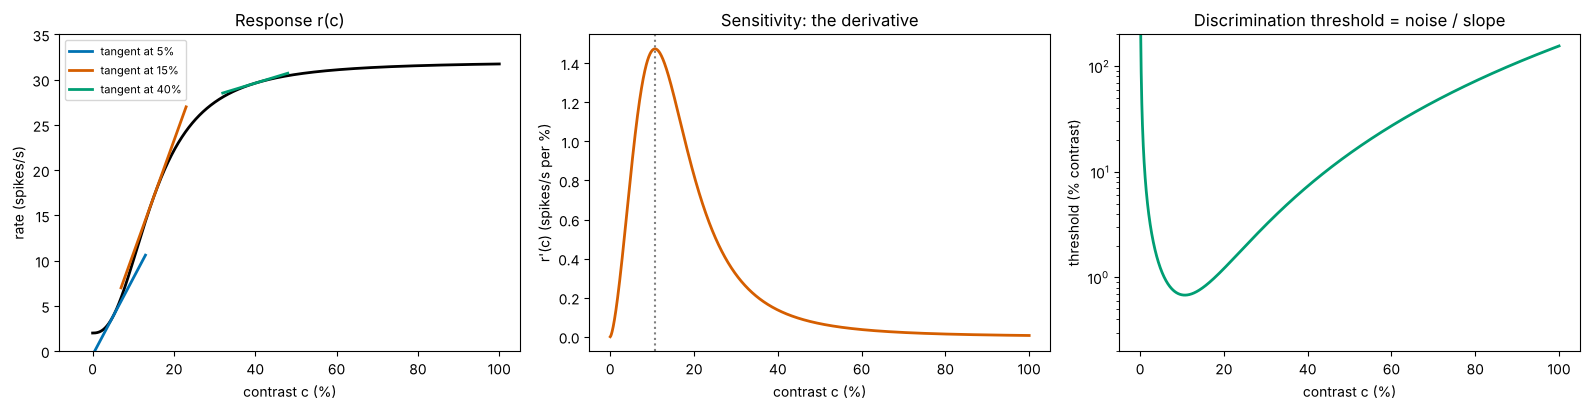

In [9]:
r0c, rmax, c50, n_nr = 2.0, 30.0, 15.0, 2.5
def nr(c):
    return r0c + rmax * c**n_nr / (c**n_nr + c50**n_nr)
def nr_prime(c):
    return rmax * n_nr * c**(n_nr - 1) * c50**n_nr / (c**n_nr + c50**n_nr)**2

cc = np.linspace(0.01, 100, 2000)
c_best = cc[np.argmax(nr_prime(cc))]
print(f"steepest at c = {c_best:.1f}% (c50 = {c50}%), slope {nr_prime(c_best):.2f} spikes/s per %")
for c_test in [5, 15, 40, 80]:
    print(f"c = {c_test:>2}%: slope {nr_prime(c_test):6.3f} spikes/s per %  ->  threshold for 1 spike/s of noise: {1 / nr_prime(c_test):6.2f}% contrast")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(cc, nr(cc), color='black', lw=2); axes[0].set_ylabel('rate (spikes/s)'); axes[0].set_title('Response r(c)')
for c_t, colour in zip([5, 15, 40], PALETTE):
    seg = np.linspace(c_t - 8, c_t + 8, 50)
    axes[0].plot(seg, nr(c_t) + nr_prime(c_t) * (seg - c_t), color=colour, lw=2, label=f'tangent at {c_t}%')
axes[0].legend(fontsize=8); axes[0].set_ylim(0, 35)
axes[1].plot(cc, nr_prime(cc), color=PALETTE[1], lw=2); axes[1].axvline(c_best, color='grey', ls=':')
axes[1].set_ylabel("r'(c) (spikes/s per %)"); axes[1].set_title('Sensitivity: the derivative')
axes[2].semilogy(cc, 1 / nr_prime(cc), color=PALETTE[2], lw=2); axes[2].set_ylim(0.2, 200)
axes[2].set_ylabel('threshold (% contrast)'); axes[2].set_title('Discrimination threshold = noise / slope')
for ax in axes:
    ax.set_xlabel('contrast c (%)')
plt.tight_layout(); plt.show()

The derivative turns "where is this neuron useful?" into a curve. The steepest point sits slightly below $c_{50}$ (a formula for it is an exercise). Populations whose $c_{50}$ values differ, each steep in a different range, cover all contrasts: one reason sensory populations are diverse.

#### Interactive version: slide along the curve

In [10]:
c_points = [2, 5, 8, 11, 13, 15, 20, 30, 45, 70, 95]
def tangent_seg(c_t):
    seg = np.linspace(max(c_t - 15, 0), min(c_t + 15, 100), 60)
    return seg, nr(c_t) + nr_prime(c_t) * (seg - c_t)
sx, sy = tangent_seg(c_points[0])
fig_tan = go.Figure([go.Scatter(x=cc[::4], y=np.round(nr(cc[::4]), 3), mode='lines', line=dict(color='black', width=3), name='r(c)'),
                     go.Scatter(x=sx, y=sy, mode='lines', line=dict(color=PALETTE[1], width=4), name='tangent line'),
                     go.Scatter(x=[c_points[0]], y=[nr(c_points[0])], mode='markers', marker=dict(size=12, color=PALETTE[1]), name='point')])
fig_tan.frames = [go.Frame(name=str(k), traces=[1, 2], data=[go.Scatter(x=tangent_seg(c_t)[0], y=tangent_seg(c_t)[1]), go.Scatter(x=[c_t], y=[nr(c_t)])],
                           layout=go.Layout(title=f"c = {c_t}%: slope r'(c) = {nr_prime(c_t):.2f} spikes/s per %;  1 spike/s of noise hides {1 / nr_prime(c_t):.1f}% of contrast"))
                  for k, c_t in enumerate(c_points)]
buttons, sliders = play_pause_and_slider(c_points, prefix='contrast (%) = ', duration=600)
fig_tan.update_layout(title=fig_tan.frames[0].layout.title.text, xaxis_title='contrast c (%)', yaxis_title='rate (spikes/s)', yaxis_range=[0, 36],
                      template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_tan.show(config=PLOTLY_CONFIG)

# **Part 4: Finite Differences — Derivatives from Numbers**

Real data come as samples, not formulas: positions every 50 ms, voltages every 0.1 ms. The derivative must be **estimated** from neighbouring values. Three standard estimates, with step $h$:

| Name | Formula | Error |
|---|---|---|
| forward | $\dfrac{f(x + h) - f(x)}{h}$ | proportional to $h$ |
| backward | $\dfrac{f(x) - f(x - h)}{h}$ | proportional to $h$ |
| central | $\dfrac{f(x + h) - f(x - h)}{2h}$ | proportional to $h^2$ |

Halving $h$ halves the error of a forward difference but **quarters** the error of a central one (the notes derive this from the linear approximation plus a curvature term). A forward difference is really the slope at the **midpoint** $x + h/2$, which is why it looks "shifted" by half a step.

### The step-size trade-off

Mathematically, smaller $h$ is always better. On a computer it is not. Each function value carries a rounding error of about $10^{-16}$ relative to its size (Lesson 8), and dividing a difference by a tiny $h$ magnifies it. Total error = **truncation** error (shrinks with $h$) + **rounding** error (grows like $10^{-16}/h$). The best $h$ balances the two.

forward difference: smallest error 6.6e-09 at h = 1e-08
central difference: smallest error 3.3e-11 at h = 3e-06


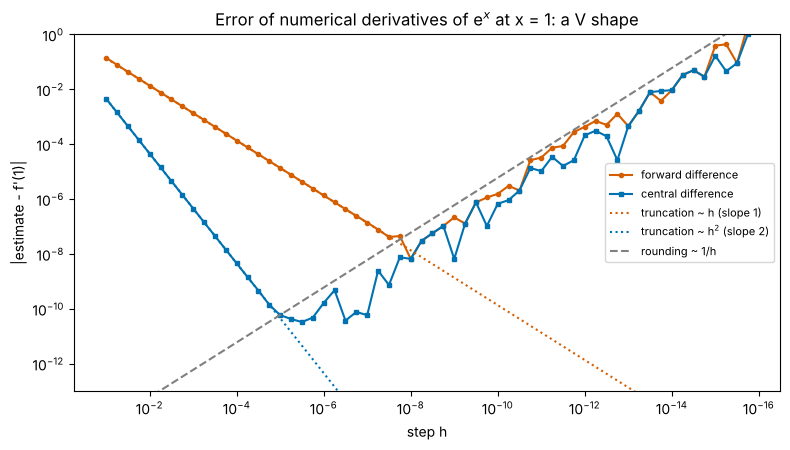

In [11]:
f, df_exact, x_eval = np.exp, np.exp(1.0), 1.0
hs = 10.0 ** -np.arange(1, 16, 0.25)
err_fwd = np.abs((f(x_eval + hs) - f(x_eval)) / hs - df_exact)
err_cen = np.abs((f(x_eval + hs) - f(x_eval - hs)) / (2 * hs) - df_exact)
print(f"forward difference: smallest error {err_fwd.min():.1e} at h = {hs[np.argmin(err_fwd)]:.0e}")
print(f"central difference: smallest error {err_cen.min():.1e} at h = {hs[np.argmin(err_cen)]:.0e}")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.loglog(hs, err_fwd + 1e-18, 'o-', ms=3, color=PALETTE[1], label='forward difference')
ax.loglog(hs, err_cen + 1e-18, 's-', ms=3, color=PALETTE[0], label='central difference')
ax.loglog(hs, hs * df_exact / 2, ':', color=PALETTE[1], label='truncation ~ h (slope 1)')
ax.loglog(hs, hs**2 * df_exact / 6, ':', color=PALETTE[0], label='truncation ~ h$^2$ (slope 2)')
ax.loglog(hs, 2.2e-16 * df_exact / hs, '--', color='grey', label='rounding ~ 1/h')
ax.set_ylim(1e-13, 1); ax.invert_xaxis()
ax.set_xlabel('step h'); ax.set_ylabel("|estimate - f'(1)|"); ax.set_title("Error of numerical derivatives of e$^x$ at x = 1: a V shape")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Reading right to left (shrinking $h$): the errors first fall along the truncation lines, slope 1 for forward and 2 for central, then turn and rise along the rounding line. The central difference reaches a few times $10^{-11}$ at $h$ between $10^{-6}$ and $10^{-5}$; the forward difference only about $10^{-8}$, at $h \approx 10^{-8}$. That is why `central_diff` above used $h = 10^{-5}$.

### Arrays of samples, and their boundaries

For sampled data, `np.gradient(y, dt)` returns central differences in the interior and one-sided (forward or backward) differences at the two ends, where there is no neighbour on one side. The ends are therefore less accurate; `edge_order=2` uses a more accurate (second-order) one-sided formula there. `np.gradient` also accepts the actual sample times when the spacing is irregular. `np.diff(y) / dt`, by contrast, returns forward differences, one fewer value than the data, each belonging to the midpoint of its interval: align them in time accordingly.

shapes: y (21,), np.gradient (21,), np.diff (20,)
error at the first sample: edge_order=1 0.214, edge_order=2 0.020;  interior (median) 0.0025  (per s)
np.diff compared at the START of each step: median error 0.052;  at the MIDPOINT: 0.0006


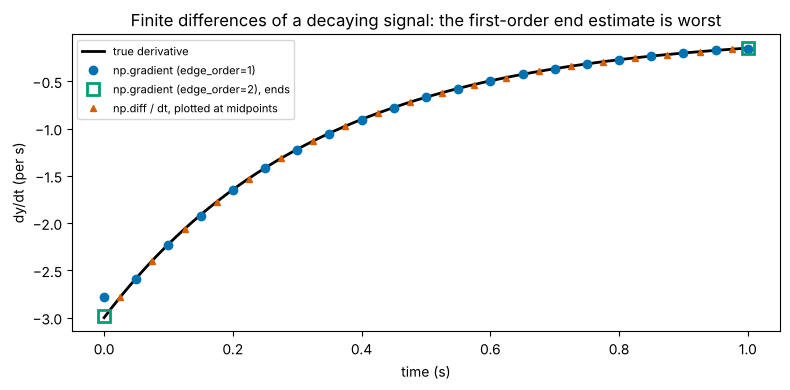

In [12]:
t = np.linspace(0, 1, 21)                         # 21 samples, dt = 0.05 s
y = np.exp(-3 * t)                                # a decaying signal (rate constant 3 per s)
dy_true = -3 * np.exp(-3 * t)
dy_g1 = np.gradient(y, t)                         # central inside, first-order one-sided at the ends
dy_g2 = np.gradient(y, t, edge_order=2)           # second-order one-sided at the ends
dy_diff = np.diff(y) / np.diff(t)                 # forward differences: 20 values
t_mid = (t[:-1] + t[1:]) / 2
print(f"shapes: y {y.shape}, np.gradient {dy_g1.shape}, np.diff {dy_diff.shape}")
print(f"error at the first sample: edge_order=1 {abs(dy_g1[0] - dy_true[0]):.3f}, edge_order=2 {abs(dy_g2[0] - dy_true[0]):.3f};  "
      f"interior (median) {np.median(np.abs(dy_g1[1:-1] - dy_true[1:-1])):.4f}  (per s)")
print(f"np.diff compared at the START of each step: median error {np.median(np.abs(dy_diff - dy_true[:-1])):.3f};  at the MIDPOINT: {np.median(np.abs(dy_diff - (-3 * np.exp(-3 * t_mid)))):.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
tf = np.linspace(0, 1, 400)
ax.plot(tf, -3 * np.exp(-3 * tf), color='black', lw=2, label='true derivative')
ax.plot(t, dy_g1, 'o', color=PALETTE[0], label='np.gradient (edge_order=1)')
ax.plot(t[[0, -1]], dy_g2[[0, -1]], 's', ms=9, mfc='none', mec=PALETTE[2], mew=2, label='np.gradient (edge_order=2), ends')
ax.plot(t_mid, dy_diff, '^', ms=5, color=PALETTE[1], label='np.diff / dt, plotted at midpoints')
ax.set_xlabel('time (s)'); ax.set_ylabel('dy/dt (per s)'); ax.set_title('Finite differences of a decaying signal: the first-order end estimate is worst')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# **Part 5: Differentiating Noisy Data**

Measurement noise is much larger than rounding error, and differentiation **amplifies** it. If each sample has independent noise with standard deviation $\sigma$, the central difference $\frac{y_{i+1} - y_{i-1}}{2h}$ has noise with standard deviation $\frac{\sqrt2\,\sigma}{2h} = \frac{\sigma}{\sqrt2\,h}$: halving the step **doubles** the noise in the derivative. Meanwhile a large step blurs genuine changes (truncation error). There is again an optimal step, now set by the noise level instead of rounding, and it is usually many samples wide.

Two standard remedies:
- use a **larger step** (a difference over several samples);
- **smooth first**, then differentiate (a Gaussian filter, as in Lessons 6 and 7).

Both trade noise for temporal resolution. A second derivative divides by $h^2$ and is far noisier still.

**Example.** A membrane capacitance $C_m$ turns voltage changes into current, $I_C = C_m\,dV/dt$. Estimating the capacitive current from a noisy voltage recording requires a derivative. Below, a neuron charges towards a new steady state, $V(t) = 10\,(1 - e^{-t/\tau})$ mV with $\tau = 10$ ms, sampled every 0.1 ms with 0.2 mV of recording noise.

method                              RMS error (mV/ms)
central, 1 sample (h = 0.1 ms)                  1.369
central, 10 samples (h = 1 ms)                  0.143
central, 40 samples (h = 4 ms)                  0.035
smooth (sigma 1 ms), then gradient              0.021
(the true derivative starts at 1.0 mV/ms and decays to 0.007)


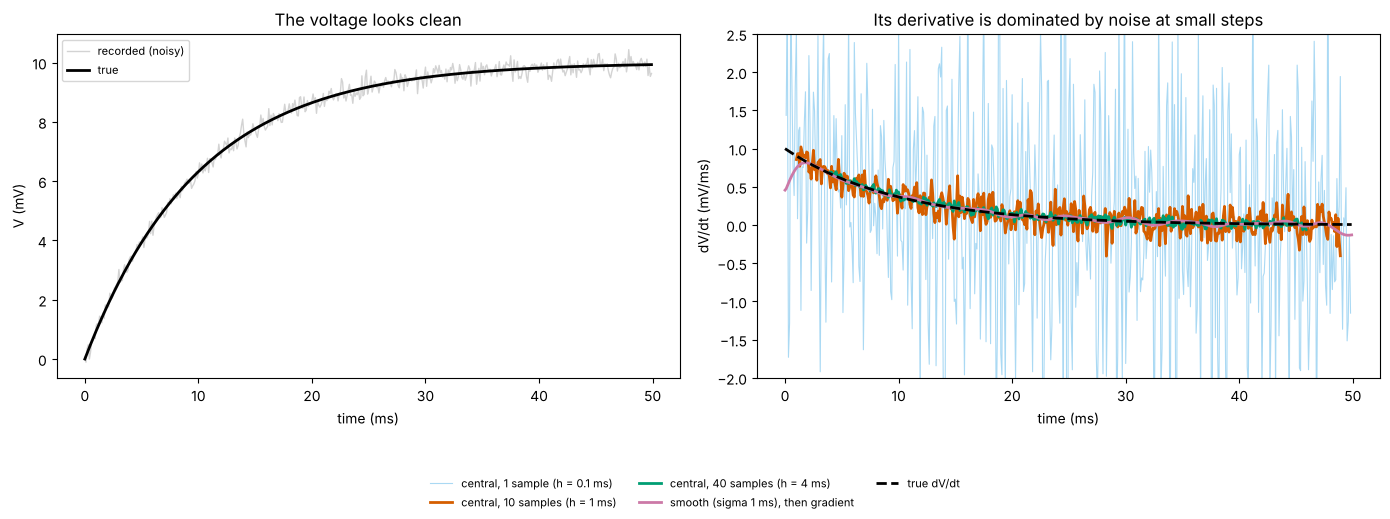

In [13]:
from scipy.ndimage import gaussian_filter1d
dt_v, tau_v = 0.1, 10.0                                            # ms
tv = np.arange(0, 50, dt_v)                                       # time (ms), shape (500,)
V_clean = 10 * (1 - np.exp(-tv / tau_v))                          # mV
V_noisy = V_clean + RNG.normal(0, 0.2, tv.size)                   # mV, 0.2 mV recording noise
dVdt_true = 10 / tau_v * np.exp(-tv / tau_v)                       # mV/ms

def central_k(y, k, dt):
    # Central difference over k samples on each side; NaN where it is not defined (the k samples at each end).
    out = np.full(y.shape, np.nan)
    out[k:-k] = (y[2 * k:] - y[:-2 * k]) / (2 * k * dt)
    return out

print(f"{'method':<34} {'RMS error (mV/ms)':>18}")
results = {}
for label, est in [('central, 1 sample (h = 0.1 ms)', central_k(V_noisy, 1, dt_v)),
                   ('central, 10 samples (h = 1 ms)', central_k(V_noisy, 10, dt_v)),
                   ('central, 40 samples (h = 4 ms)', central_k(V_noisy, 40, dt_v)),
                   ('smooth (sigma 1 ms), then gradient', np.gradient(gaussian_filter1d(V_noisy, 10, mode='nearest'), dt_v))]:
    inner = slice(40, -40)                                          # compare all methods on the same interior samples
    results[label] = est
    print(f"{label:<34} {np.sqrt(np.nanmean((est[inner] - dVdt_true[inner])**2)):>18.3f}")
print(f"(the true derivative starts at {dVdt_true[0]:.1f} mV/ms and decays to {dVdt_true[-1]:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].plot(tv, V_noisy, color='lightgrey', lw=1, label='recorded (noisy)'); axes[0].plot(tv, V_clean, color='black', lw=2, label='true')
axes[0].set_xlabel('time (ms)'); axes[0].set_ylabel('V (mV)'); axes[0].set_title('The voltage looks clean'); axes[0].legend(fontsize=8)
for (label, est), colour in zip(results.items(), [PALETTE[5], PALETTE[1], PALETTE[2], PALETTE[3]]):
    axes[1].plot(tv, est, color=colour, lw=0.8 if '0.1 ms' in label else 2, alpha=0.5 if '0.1 ms' in label else 1, zorder=1 if '0.1 ms' in label else 2, label=label)
axes[1].plot(tv, dVdt_true, color='black', lw=2, ls='--', label='true dV/dt')
axes[1].set_ylim(-2, 2.5); axes[1].set_xlabel('time (ms)'); axes[1].set_ylabel('dV/dt (mV/ms)')
axes[1].set_title('Its derivative is dominated by noise at small steps'); fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.14, 1, 1)); plt.show()

Noise of 0.2 mV, invisible in the voltage trace, swamps the 0.1 ms derivative completely ($\sigma/(\sqrt2 h) \approx 1.4$ mV/ms, more than the signal). A 1 ms step brings the error down about tenfold; a 4 ms step and a 1 ms Gaussian smoothing do better still on this slowly changing signal. The price is time resolution: the 4 ms step gives no estimate at all in the first and last 4 ms, the smoothed estimate is pulled down at the very start (the filter has to invent values before $t = 0$: another boundary effect), and on a signal that changes within a few milliseconds (a spike) the same smoothing would flatten exactly the feature of interest. **The right step depends on both the noise level and how fast the true signal changes**, and it should be chosen and reported, not left at "one sample".

# **Part 6: Mini-Lab — From Hand Position to Velocity and Acceleration**

The motor-cortex recording used since Lesson 2 ([Stevenson et al., 2011](https://doi.org/10.1152/jn.00626.2010); [DREAM on CRCNS](https://crcns.org/data-sets/movements/dream); packaged by [Benjamin et al., 2018](https://github.com/KordingLab/spykesML)) contains the monkey's **hand position** as well as its **hand velocity**, both sampled every 50 ms. Velocity is the time derivative of position, so we can differentiate the recorded position ourselves and check the result against the recorded velocity: a rare chance to test numerical differentiation against an independent answer.

**Plan.**
1. Compare forward and central differences of position with the recorded velocity.
2. Add simulated tracking noise to the position and find the best step size.
3. Differentiate once more to get acceleration.
4. Use the derivative of Lesson 8's fitted speed-response function to describe how sensitive one neuron is to speed.

In [14]:
import os, urllib.request
from scipy.io import loadmat

M1_FILE = 'm1_stevenson_2011.mat'
if not os.path.exists(M1_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/KordingLab/spykesML/ff2b1830ae07909e5f1a0811445ca3fd5732dc6f/data/' + M1_FILE, M1_FILE)
m1 = loadmat(M1_FILE)
t_m1 = m1['time'].ravel()                                          # s, shape (15536,)
pos = m1['handPos'][:2].T * 100                                    # shape (15536, 2): hand position (x, y), cm
vel = m1['handVel'][:2].T * 100                                    # shape (15536, 2): recorded hand velocity, cm/s
dt = 0.05
print("pos:", pos.shape, "cm;  vel:", vel.shape, "cm/s")
print("sample intervals (s):", np.unique(np.round(np.diff(t_m1), 4)), " -> regular, no gaps")

fwd = np.diff(pos, axis=0) / dt                                    # forward differences, shape (15535, 2): belong to the midpoints
cen = np.gradient(pos, dt, axis=0)                                 # central differences (one-sided at the two ends), shape (15536, 2)
rms = lambda a, b: np.sqrt(np.mean((a - b)**2))
print(f"forward difference vs recorded velocity at the START of each step : RMS {rms(fwd, vel[:-1]):.2f} cm/s")
print(f"forward difference vs recorded velocity at the MIDPOINT (average)  : RMS {rms(fwd, (vel[:-1] + vel[1:]) / 2):.2f} cm/s")
print(f"central difference vs recorded velocity at the same sample        : RMS {rms(cen, vel):.2f} cm/s   (velocity s.d. {vel.std():.1f} cm/s)")

pos: (15536, 2) cm;  vel: (15536, 2) cm/s
sample intervals (s): [0.0495 0.05   0.0505]  -> regular, no gaps
forward difference vs recorded velocity at the START of each step : RMS 1.07 cm/s
forward difference vs recorded velocity at the MIDPOINT (average)  : RMS 0.27 cm/s
central difference vs recorded velocity at the same sample        : RMS 0.41 cm/s   (velocity s.d. 5.8 cm/s)


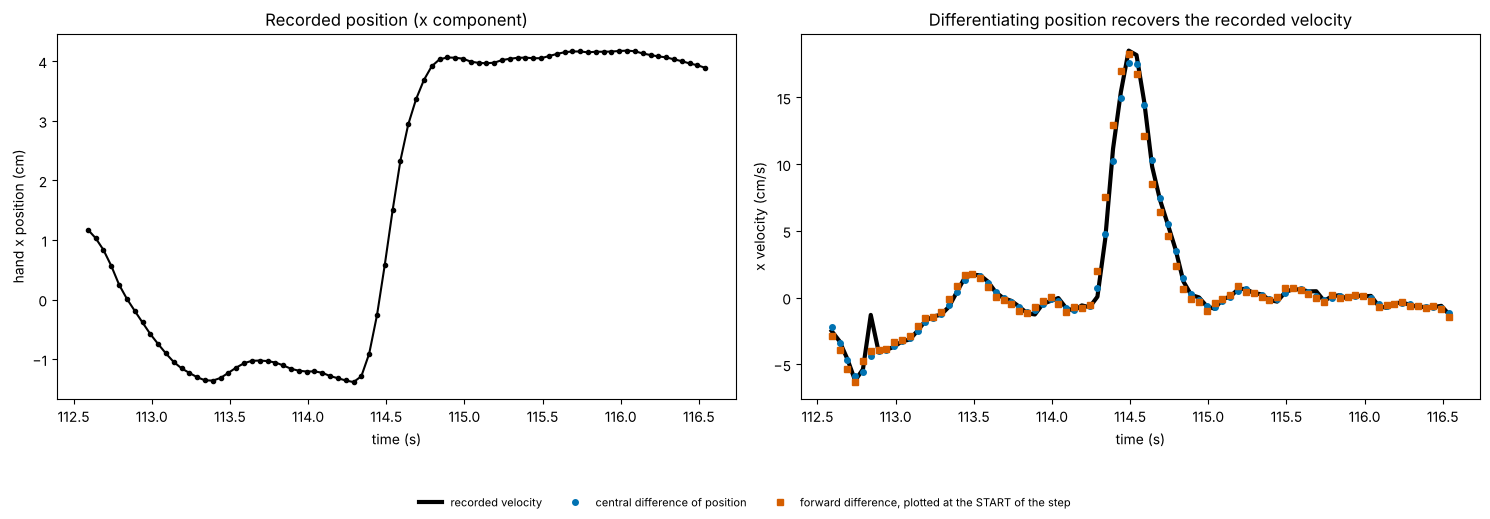

In [15]:
seg = slice(2000, 2080)                                            # 4 s of reaching
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].plot(t_m1[seg], pos[seg, 0], 'o-', ms=3, color='black')
axes[0].set_xlabel('time (s)'); axes[0].set_ylabel('hand x position (cm)'); axes[0].set_title('Recorded position (x component)')
axes[1].plot(t_m1[seg], vel[seg, 0], color='black', lw=3, label='recorded velocity')
axes[1].plot(t_m1[seg], cen[seg, 0], 'o', ms=4, color=PALETTE[0], label='central difference of position')
axes[1].plot(t_m1[2000:2080], fwd[2000:2080, 0], 's', ms=4, color=PALETTE[1], label='forward difference, plotted at the START of the step')
axes[1].set_xlabel('time (s)'); axes[1].set_ylabel('x velocity (cm/s)'); axes[1].set_title('Differentiating position recovers the recorded velocity')
fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

The central difference agrees with the recorded velocity to within about 0.4 cm/s, against a velocity standard deviation of about 6 cm/s. The forward difference looks **early**: plotted at the start of each step, it is off by about 1 cm/s; compared with the velocity half a step later (the average of the two ends), it agrees to about 0.25 cm/s. A forward difference is the derivative at the midpoint of its step.

### The step-size trade-off on a real trajectory

The recorded position is very smooth (it was filtered by the recording system). Real tracking, from a camera say, has jitter. We add Gaussian noise of 0.05 cm or 0.2 cm to the recorded position and estimate velocity by central differences over $k$ samples, $h = k \times 50$ ms.

position noise 0.00 cm: RMS velocity error for k = [1, 2, 3, 4, 6, 8]: [0.41 0.98 1.56 2.09 2.91 3.5 ] cm/s;  best k = 1
position noise 0.05 cm: RMS velocity error for k = [1, 2, 3, 4, 6, 8]: [0.82 1.04 1.58 2.1  2.92 3.5 ] cm/s;  best k = 1
position noise 0.20 cm: RMS velocity error for k = [1, 2, 3, 4, 6, 8]: [2.87 1.71 1.82 2.2  2.95 3.52] cm/s;  best k = 2


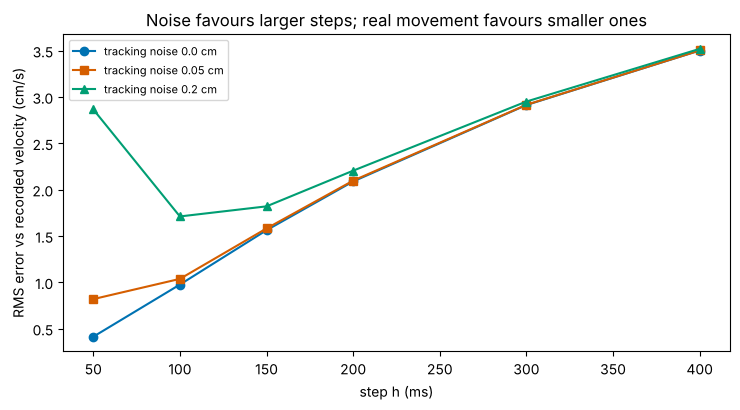

In [16]:
ks = [1, 2, 3, 4, 6, 8]
rng_noise = np.random.default_rng(0)
step_err = {}
for noise_sd in [0.0, 0.05, 0.2]:
    p_noisy = pos + rng_noise.normal(0, noise_sd, pos.shape)
    errs = []
    for k in ks:
        est = (p_noisy[2 * k:] - p_noisy[:-2 * k]) / (2 * k * dt)          # centred on samples k ... T-k-1
        errs.append(rms(est, vel[k:-k]))
    step_err[noise_sd] = errs
    print(f"position noise {noise_sd:4.2f} cm: RMS velocity error for k = {ks}: {np.round(errs, 2)} cm/s;  best k = {ks[int(np.argmin(errs))]}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (noise_sd, errs), colour, mk in zip(step_err.items(), PALETTE, MARKERS):
    ax.plot(np.array(ks) * 50, errs, marker=mk, color=colour, label=f'tracking noise {noise_sd} cm')
ax.set_xlabel('step h (ms)'); ax.set_ylabel('RMS error vs recorded velocity (cm/s)')
ax.set_title('Noise favours larger steps; real movement favours smaller ones'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Without added noise the smallest step is best: the error grows steadily with $h$ because a long step blurs the changing velocity (truncation). With 0.2 cm of jitter the one-sample estimate is ruined by noise ($0.2/(\sqrt2 \times 0.05) \approx 2.8$ cm/s), and a 100 ms step is best. The optimum moves exactly as Part 5 predicted.

### Acceleration: a second derivative

acceleration s.d.: from velocity 36.4 cm/s^2, from position (twice) 33.0 cm/s^2;  RMS difference 6.2 cm/s^2
with 0.05 cm tracking noise, acceleration error from twice-differentiated position: RMS 12.1 cm/s^2
with 0.2 cm tracking noise, acceleration error from twice-differentiated position: RMS 48.4 cm/s^2


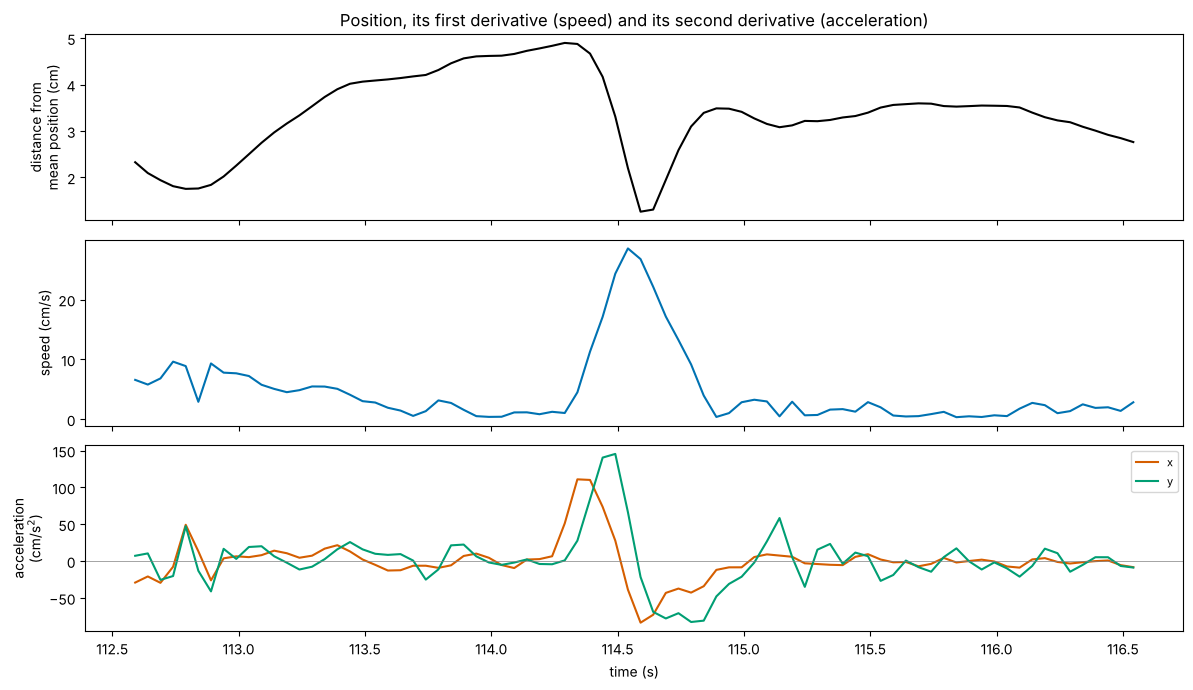

In [17]:
acc_from_vel = np.gradient(vel, dt, axis=0)                         # cm/s^2, differentiate the recorded velocity once
acc_from_pos = np.gradient(np.gradient(pos, dt, axis=0), dt, axis=0) # differentiate position twice
speed = np.linalg.norm(vel, axis=1)
print(f"acceleration s.d.: from velocity {acc_from_vel.std():.1f} cm/s^2, from position (twice) {acc_from_pos.std():.1f} cm/s^2;  "
      f"RMS difference {rms(acc_from_vel, acc_from_pos):.1f} cm/s^2")
for noise_sd in [0.05, 0.2]:
    p_noisy = pos + np.random.default_rng(1).normal(0, noise_sd, pos.shape)
    a_noisy = np.gradient(np.gradient(p_noisy, dt, axis=0), dt, axis=0)
    print(f"with {noise_sd} cm tracking noise, acceleration error from twice-differentiated position: RMS {rms(a_noisy, acc_from_pos):.1f} cm/s^2")

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(t_m1[seg], np.linalg.norm(pos[seg] - pos[seg].mean(axis=0), axis=1), color='black'); axes[0].set_ylabel('distance from\nmean position (cm)')
axes[1].plot(t_m1[seg], speed[seg], color=PALETTE[0]); axes[1].set_ylabel('speed (cm/s)')
axes[2].plot(t_m1[seg], acc_from_vel[seg, 0], color=PALETTE[1], label='x'); axes[2].plot(t_m1[seg], acc_from_vel[seg, 1], color=PALETTE[2], label='y')
axes[2].axhline(0, color='grey', lw=0.5); axes[2].set_ylabel('acceleration\n(cm/s$^2$)'); axes[2].legend(fontsize=8, loc='upper right')
axes[2].set_xlabel('time (s)'); axes[0].set_title('Position, its first derivative (speed) and its second derivative (acceleration)')
plt.tight_layout(); plt.show()

On the smooth recorded trajectory, differentiating position twice gives nearly the same acceleration as differentiating velocity once. With realistic tracking noise it does not: the second difference divides the noise by $h^2$, and 0.2 cm of jitter produces acceleration errors (48 cm/s$^2$ RMS) larger than the spread of the acceleration itself (s.d. about 36 cm/s$^2$). **Second derivatives of measured data need much more smoothing than first derivatives.**

### A neuron's sensitivity to speed

Finally, return to the motivating neuron. Its fitted response $r(s) = r_0 + A(1 - e^{-s/s_0})$ has derivative $r'(s) = \frac{A}{s_0}e^{-s/s_0}$. How large is the sensitivity during typical movements, and how good is the linear approximation $\Delta r \approx r'(s)\,\Delta s$ for the speed changes that actually occur in one 50 ms bin?

10th percentile speed   0.5 cm/s: sensitivity r'(s) = 5.19 spikes/s per cm/s
50th percentile speed   3.1 cm/s: sensitivity r'(s) = 4.10 spikes/s per cm/s
90th percentile speed  12.8 cm/s: sensitivity r'(s) = 1.69 spikes/s per cm/s
typical |speed change| per bin: median 0.86, 90th percentile 3.54 cm/s
linear approximation of the rate change: median relative error 3.9%, 90th percentile 16.0%


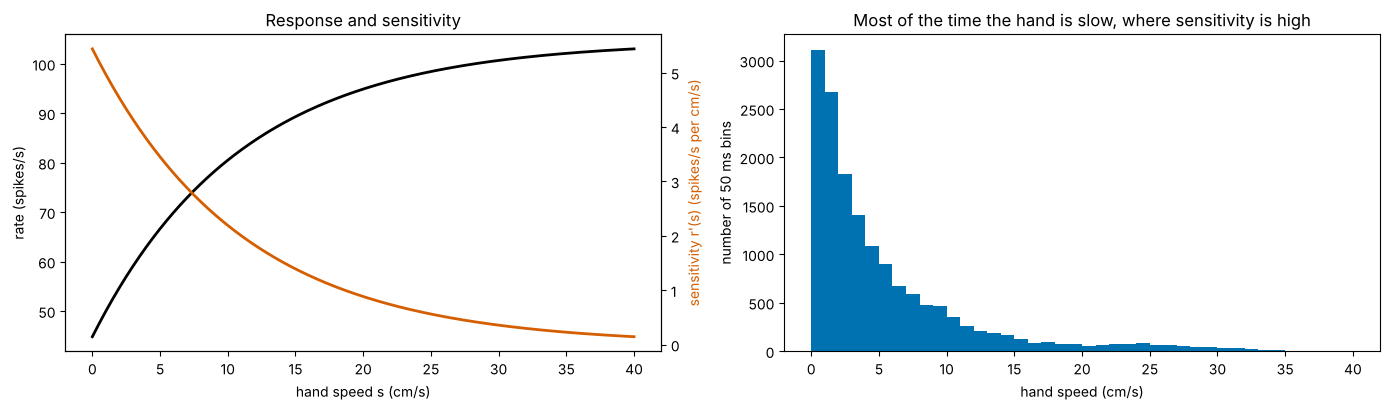

In [18]:
def r_prime(s_):
    return A / s0 * np.exp(-s_ / s0)                               # spikes/s per cm/s
pct = np.percentile(speed, [10, 50, 90])
for p_lab, sp in zip(['10th', '50th', '90th'], pct):
    print(f"{p_lab} percentile speed {sp:5.1f} cm/s: sensitivity r'(s) = {r_prime(sp):.2f} spikes/s per cm/s")

ds = np.diff(speed)                                                 # speed change in one 50 ms bin (cm/s)
exact_dr = rate_of_speed(speed[1:]) - rate_of_speed(speed[:-1])
linear_dr = r_prime(speed[:-1]) * ds
rel_err = np.abs(linear_dr - exact_dr) / np.maximum(np.abs(exact_dr), 1e-9)
print(f"typical |speed change| per bin: median {np.median(np.abs(ds)):.2f}, 90th percentile {np.percentile(np.abs(ds), 90):.2f} cm/s")
print(f"linear approximation of the rate change: median relative error {np.median(rel_err):.1%}, 90th percentile {np.percentile(rel_err, 90):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sg = np.linspace(0, 40, 401)
ax2 = axes[0].twinx()
axes[0].plot(sg, rate_of_speed(sg), color='black', lw=2, label='r(s)')
ax2.plot(sg, r_prime(sg), color=PALETTE[1], lw=2, label="r'(s)")
axes[0].set_xlabel('hand speed s (cm/s)'); axes[0].set_ylabel('rate (spikes/s)'); ax2.set_ylabel("sensitivity r'(s) (spikes/s per cm/s)", color=PALETTE[1])
axes[0].set_title('Response and sensitivity')
axes[1].hist(speed, bins=np.linspace(0, 40, 41), color=PALETTE[0])
axes[1].set_xlabel('hand speed (cm/s)'); axes[1].set_ylabel('number of 50 ms bins'); axes[1].set_title('Most of the time the hand is slow, where sensitivity is high')
plt.tight_layout(); plt.show()

**Interpretation.**
- Differentiating the recorded position reproduces the independently recorded velocity to within about 7% of its spread, once the right formula and alignment are used (central differences, or forward differences assigned to midpoints).
- With tracking noise, the best differentiation step lengthens: one sample with clean data, two samples (100 ms) with 0.2 cm of jitter.
- A second derivative of noisy position is unusable without smoothing.
- The neuron's sensitivity to speed is highest when the hand is slow, which is most of the time. For the speed changes that occur within one bin (median 0.9 cm/s), the linear approximation predicts the rate change to within 4% (median); for the largest 10% of changes, above 3.5 cm/s, the error exceeds 16%, because the curve bends within the step.

**Limitations.** The recorded position had already been filtered, so its smoothness flatters numerical differentiation; real raw tracking is noisier. The tracking noise added here is simulated. The neuron's response function is the Lesson 8 fit, with its own uncertainty, and ignores direction.

# **Part 7: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Derivative as rate of change | velocity and acceleration from tracking; $dV/dt$ in membrane equations (Lesson 21) | rates of change of loss during training |
| Sensitivity, $\Delta f \approx f'\,\Delta x$ | discrimination thresholds from tuning-curve slopes; Fisher information of a population | gradients: how the loss changes per unit change of each weight (Lessons 10, 12) |
| Activation derivatives | gain of a neuron at its operating point | backpropagation multiplies them; saturation gives vanishing gradients |
| Finite differences and gradient checks | estimating derivatives from samples | checking hand-written gradients; numerical optimisation |
| Noise amplification | smoothing before computing velocity, acceleration, or capacitive current | noisy gradients in stochastic gradient descent (Lesson 12) |
| Step-size trade-off | choosing the differentiation window | choosing $h$ in gradient checks; learning rates (a different "step", Lesson 12) |

**Slope and discrimination.** A classic result of sensory neuroscience is that a neuron discriminates best where its tuning curve is **steepest**, not where it responds most: at the flanks of an orientation tuning curve rather than at its peak. The local linear approximation $\delta\theta \approx \delta r / |r'(\theta)|$ is the reason, and population measures of sensitivity such as the Fisher information are built from the squared slopes of many tuning curves.

# **Part 8: Summary and Lesson 10 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Difference quotient | $\frac{f(x + h) - f(x)}{h}$ | slope of a secant; depends on $h$ |
| Derivative | $f'(x) = \lim_{h \to 0}\frac{f(x + h) - f(x)}{h}$ | slope of the tangent; units: output per input |
| Differentiability | the limit exists | fails at corners (ReLU at 0) and jumps |
| Rules | power, sum, product, quotient, $e^{ax}$, $\ln x$, $\sin$, $\cos$ | check with a central difference |
| Activation derivatives | $\sigma(1 - \sigma)$, $1 - \tanh^2$, step, $\sigma$ | saturated activations have tiny slopes |
| Linear approximation | $\Delta f \approx f'(x)\,\Delta x$ | sensitivity; error grows like $(\Delta x)^2$ |
| Discrimination | threshold $\approx$ noise / slope | neurons are most useful where steepest |
| Finite differences | forward/backward error $\propto h$, central $\propto h^2$ | forward differences belong to midpoints |
| Step-size trade-off | truncation vs rounding or noise | central $h \approx 10^{-5}$ for exact functions; several samples for noisy data |
| Noisy data | noise in derivative $\approx \sigma/(\sqrt2 h)$ | smooth or widen the step; second derivatives are much worse |

**Lesson 10 — Chain rule and backpropagation** handles functions inside functions. If the rate depends on a weighted input, and the weighted input on the weights, how does the rate change with each weight? The chain rule multiplies the derivatives along the chain, and backpropagation organises that multiplication for a whole network.